# Krok 6: wykresy do README

Wykresy liczone wyłącznie z plików w `data/` (wyniki zapytań SQL i modelu z notatnika 5b). Styl wspólny z projektem TheLook (`viz_style.py`). Pliki PNG trafiają do `docs/img/`.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

from viz_style import COLORS, apply_style, legend_outside

apply_style()
IMG_DIR = Path("docs/img")
IMG_DIR.mkdir(parents=True, exist_ok=True)

NOT_SIGNIFICANT_GRAY = "#858b94"       # szary dla efektów nieistotnych: kontrast 3,4:1 na białym tle
CHANGE_DATE = pd.Timestamp("2018-08-27")
HALF_WEEK = pd.Timedelta(days=3.5)


def pl_number(value: float, decimals: int = 1) -> str:
    """Liczba z przecinkiem dziesiętnym, np. 23,1."""
    return f"{value:.{decimals}f}".replace(".", ",")

## Wykres 1: D1 tygodniowych kohort przed i od 27.08

Punkty: D1 każdej kohorty tygodniowej z 95% przedziałem (`sql/step4b_retention_by_week.sql`). Poziome linie: D1 całego okresu (`sql/step4c_retention_two_periods.sql`).

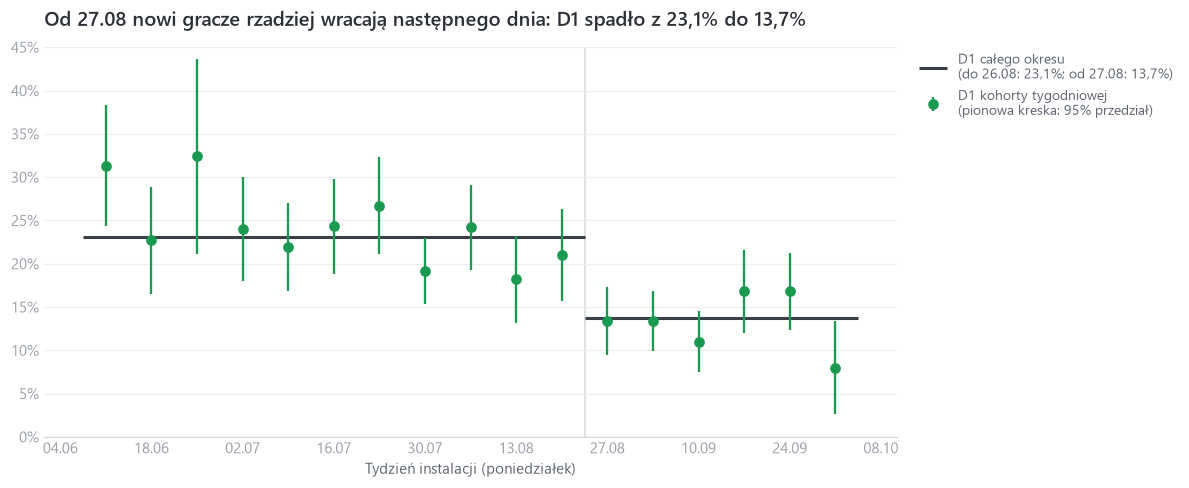

In [2]:
weekly = (
    pd.read_csv("data/step4b_retention_by_week.csv", parse_dates=["cohort_week"])
    .assign(cohort_period=lambda d: np.where(d["cohort_week"] < CHANGE_DATE,
                                             "1_do_2018-08-26", "2_od_2018-08-27"))
)
period_lines = (
    weekly
    .groupby("cohort_period")
    .agg(first_week=("cohort_week", "min"), last_week=("cohort_week", "max"))
    .join(pd.read_csv("data/step4c_retention_two_periods.csv")
          .set_index("cohort_period")[["d1_retention_pct"]])
)

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.errorbar(
    weekly["cohort_week"], weekly["d1_retention_pct"], yerr=weekly["d1_margin_pp"],
    fmt="o", markersize=6, color=COLORS["series_1"], elinewidth=1.5, capsize=0,
    label="D1 kohorty tygodniowej\n(pionowa kreska: 95% przedział)",
)
before_pct, after_pct = period_lines["d1_retention_pct"]
PERIOD_LEGEND = (f"D1 całego okresu\n(do 26.08: {pl_number(before_pct)}%; "
                 f"od 27.08: {pl_number(after_pct)}%)")
for i, row in enumerate(period_lines.itertuples()):
    ax.hlines(row.d1_retention_pct, row.first_week - HALF_WEEK, row.last_week + HALF_WEEK,
              color=COLORS["series_2"], linewidth=2,
              label=PERIOD_LEGEND if i == 0 else None, zorder=1)
ax.axvline(CHANGE_DATE - HALF_WEEK, color=COLORS["axis"], linewidth=1, zorder=0)
ax.set_ylim(0, 45)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
ax.set_xlabel("Tydzień instalacji (poniedziałek)")
ax.set_title(f"Od 27.08 nowi gracze rzadziej wracają następnego dnia: "
             f"D1 spadło z {pl_number(before_pct)}% do {pl_number(after_pct)}%")
legend_outside(ax)
fig.savefig(IMG_DIR / "d1_retention_by_week.png", dpi=150, bbox_inches="tight")
plt.show()

## Wykres 2: ilorazy szans z modelu B

Źródło: `data/step5b_odds_ratios_model_b.csv` (notatnik `step5b_model_d1.ipynb`, sekcja 7). Zielone wypełnione punkty: efekty istotne (p < 0,05); szare puste: nieistotne (przedział obejmuje 1). Skala logarytmiczna, żeby efekty „×2” i „×0,5” były tak samo daleko od 1.

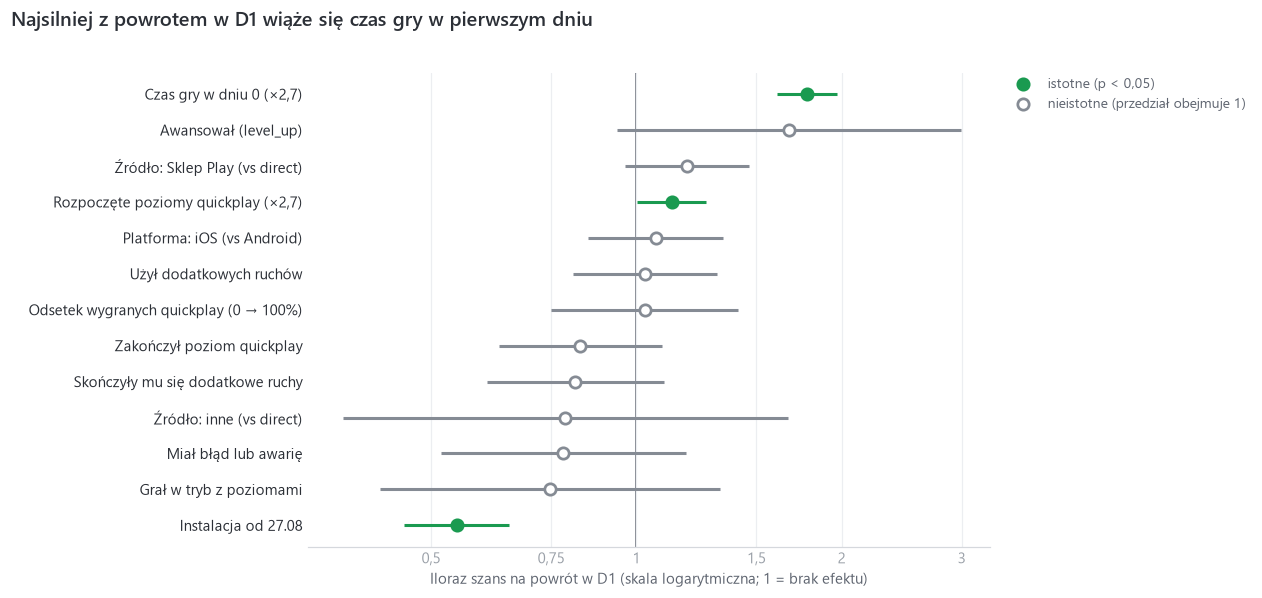

In [3]:
FEATURE_LABELS = {
    "log_engagement_minutes_d0": "Czas gry w dniu 0 (×2,7)",
    "leveled_up_d0": "Awansował (level_up)",
    "source_group[google-play_organic]": "Źródło: Sklep Play (vs direct)",
    "log_quickplay_levels_started_d0": "Rozpoczęte poziomy quickplay (×2,7)",
    "platform[IOS]": "Platforma: iOS (vs Android)",
    "used_extra_steps_d0": "Użył dodatkowych ruchów",
    "quickplay_win_rate_d0": "Odsetek wygranych quickplay (0 → 100%)",
    "finished_quickplay_level_d0": "Zakończył poziom quickplay",
    "ran_out_of_extra_steps_d0": "Skończyły mu się dodatkowe ruchy",
    "source_group[inne]": "Źródło: inne (vs direct)",
    "had_error_d0": "Miał błąd lub awarię",
    "played_level_mode_d0": "Grał w tryb z poziomami",
    "after_0827": "Instalacja od 27.08",
}
odds = (
    pd.read_csv("data/step5b_odds_ratios_model_b.csv")
    .assign(
        label=lambda d: d["feature"].map(FEATURE_LABELS),
        significant=lambda d: d["p_value"].lt(0.05),
    )
    .sort_values("odds_ratio")
    .reset_index(drop=True)
    .assign(y=lambda d: d.index)
)

fig, ax = plt.subplots(figsize=(10, 5.6))
fig.subplots_adjust(left=0.28)                          # etykiety cech mieszczą się w rysunku, tytuł równa się z nimi
for significant in [True, False]:                      # kolejność w legendzie: najpierw istotne
    group = odds.query("significant == @significant")
    color = COLORS["series_1"] if significant else NOT_SIGNIFICANT_GRAY
    ax.hlines(group["y"], group["ci_low"], group["ci_high"], color=color, linewidth=2)
    ax.scatter(group["odds_ratio"], group["y"], s=55, zorder=3, linewidth=1.8,
               facecolor=color if significant else COLORS["surface"], edgecolor=color,
               label="istotne (p < 0,05)" if significant else "nieistotne (przedział obejmuje 1)")
ax.axvline(1, color=COLORS["text_secondary"], linewidth=1, zorder=0)
ax.set_xscale("log")
ax.set_xlim(0.33, 3.3)
ax.xaxis.set_major_locator(FixedLocator([0.5, 0.75, 1, 1.5, 2, 3]))
ax.xaxis.set_minor_locator(NullLocator())
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: pl_number(v, 2).rstrip("0").rstrip(",")))
ax.set_yticks(odds["y"], odds["label"])
ax.tick_params(axis="y", colors=COLORS["text_primary"])
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Iloraz szans na powrót w D1 (skala logarytmiczna; 1 = brak efektu)")
fig.suptitle("Najsilniej z powrotem w D1 wiąże się czas gry w pierwszym dniu",
             x=0.01, ha="left", fontsize=13, fontweight="semibold", color=COLORS["text_primary"])
legend_outside(ax)
fig.savefig(IMG_DIR / "d1_odds_ratios.png", dpi=150, bbox_inches="tight")
plt.show()